In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path        


In [18]:
output_tag = "olmo_career"
output_name = f"lossvsscore_{output_tag}"
OUTPUT_DIR = Path("/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/outputs/plots")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [34]:
d = np.load("/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/scped_IFS/token_scores_olmo_career.npz")
df = pd.DataFrame({k: d[k] for k in d.files})
print("df.head(10):\n ", df.tail(10))

df.head(10):
          example_idx  position  token_id        score
386891         5899        95       690   756.086914
386892         5899        96      6089  1811.951660
386893         5899        97     15025   244.861816
386894         5899        98      1139    93.506378
386895         5899        99      6968  -764.348206
386896         5899       100      2731  1168.837158
386897         5899       101      7528  -367.298645
386898         5899       102      1217   186.325409
386899         5899       103     25066   164.463379
386900         5899       104        13    40.172546


In [33]:
loss_base = np.load("/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/token_losses/token_loss_base.npz")
loss_base_df = pd.DataFrame({k: loss_base[k] for k in loss_base.files})

loss_finetuned = np.load("/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/token_losses/token_loss_finetuned.npz")
loss_finetuned_df = pd.DataFrame({k: loss_finetuned[k] for k in loss_finetuned.files})

print("loss_base_df.head(10):\n", loss_base_df.tail(10))
print("loss_finetuned_df.head(10): \n", loss_finetuned_df.tail(10))


print(f"scores:          {len(df)} rows, {df['example_idx'].nunique()} documents")
print(f"base loss:       {len(loss_base_df)} rows, {loss_base_df['example_idx'].nunique()} documents")
print(f"finetuned loss:  {len(loss_finetuned_df)} rows, {loss_finetuned_df['example_idx'].nunique()} documents")

loss_base_df.head(10):
         example_idx  position  token_id      loss
386891         5899        95       690  1.625000
386892         5899        96      6089  3.281250
386893         5899        97     15025  3.171875
386894         5899        98      1139  2.125000
386895         5899        99      6968  1.921875
386896         5899       100      2731  4.906250
386897         5899       101      7528  4.937500
386898         5899       102      1217  2.203125
386899         5899       103     25066  1.414062
386900         5899       104        13  0.554688
loss_finetuned_df.head(10): 
         example_idx  position  token_id      loss
386891         5899        95       690  1.218750
386892         5899        96      6089  1.648438
386893         5899        97     15025  0.470703
386894         5899        98      1139  1.312500
386895         5899        99      6968  2.500000
386896         5899       100      2731  0.824219
386897         5899       101      7528  1.968

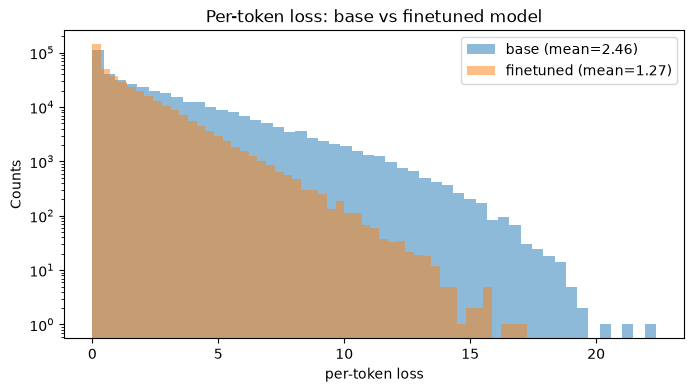

base loss:      mean=2.462  median=1.492
finetuned loss: mean=1.271  median=0.691


In [39]:
# Overlaid, density-normalized so the two (same number of tokens anyway)
# are directly comparable. log y-scale since loss is heavy-tailed -- most
# tokens have small loss, a minority are much higher.
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(loss_base_df["loss"], bins=50, alpha=0.5, density=False,
        label=f"base (mean={loss_base_df['loss'].mean():.2f})")
ax.hist(loss_finetuned_df["loss"], bins=50, alpha=0.5, density=False,
        label=f"finetuned (mean={loss_finetuned_df['loss'].mean():.2f})")
ax.set_yscale("log")
ax.set_xlabel("per-token loss")
ax.set_ylabel("Counts")
ax.set_title("Per-token loss: base vs finetuned model")
ax.legend()
fig.savefig(OUTPUT_DIR / f"{output_name}_loss_histogram.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"base loss:      mean={loss_base_df['loss'].mean():.3f}  median={loss_base_df['loss'].median():.3f}")
print(f"finetuned loss: mean={loss_finetuned_df['loss'].mean():.3f}  median={loss_finetuned_df['loss'].median():.3f}")

In [38]:
# Merge base and finetuned loss on (example_idx, position). token_id should
# match exactly between the two -- they came from the same tokenized
# dataset -- so this also doubles as a check that nothing is misaligned
# between the two loss runs themselves before bringing scores into it.
loss_merged = loss_base_df.merge(
    loss_finetuned_df, on=["example_idx", "position"], suffixes=("_base", "_finetuned")
)
base_finetuned_mismatches = (loss_merged["token_id_base"] != loss_merged["token_id_finetuned"]).sum()
print(f"{len(loss_merged)} tokens merged (of {len(loss_base_df)} base / {len(loss_finetuned_df)} finetuned)")
print(f"token_id mismatches between base/finetuned: {base_finetuned_mismatches}")

# Positive = finetuned loss is lower than base here, i.e. this is a token the
# model "learned" during finetuning.
loss_merged["loss_diff"] = loss_merged["loss_base"] - loss_merged["loss_finetuned"]

# Now join against the IF scores on the same key. This is the real test of
# the open question from compute_token_loss.py: does "position" mean the
# same thing in both files? If token_id doesn't match here, that assumption
# was wrong and needs fixing before trusting anything below.
combined = loss_merged.merge(
    df[["example_idx", "position", "token_id", "score"]], on=["example_idx", "position"]
)
print(combined.head(10))
score_mismatches = (combined["token_id_base"] != combined["token_id"]).sum()
print(f"{len(combined)} tokens joined with scores")
print(f"token_id mismatches vs scores: {score_mismatches}")

386901 tokens merged (of 386901 base / 386901 finetuned)
token_id mismatches between base/finetuned: 0
   example_idx  position  token_id_base  loss_base  token_id_finetuned  \
0            0        74           1271   2.359375                1271   
1            0        75           3480   5.156250                3480   
2            0        76            505   0.480469                 505   
3            0        77          33400   0.769531               33400   
4            0        78            311   0.024536                 311   
5            0        79           3241   0.024780                3241   
6            0        80          15009   0.017700               15009   
7            0        81             11   2.281250                  11   
8            0        82            499   0.550781                 499   
9            0        83            649   2.390625                 649   

   loss_finetuned  loss_diff  token_id        score  
0        0.326172   2.033203

Spearman correlation(loss_diff, score) = 0.1774  (p=0.00e+00)


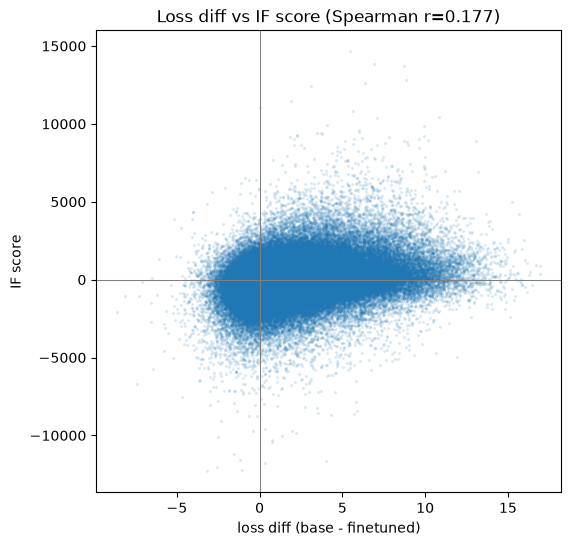

In [36]:
from scipy.stats import spearmanr

# Spearman, not Pearson -- same reasoning as everywhere else in this
# project: scores are heavy-tailed/outlier-dominated, and rank is what
# actually matters for the downstream remove_top_X% selection, not raw
# magnitude.
corr, pval = spearmanr(combined["loss_diff"], combined["score"])
print(f"Spearman correlation(loss_diff, score) = {corr:.4f}  (p={pval:.2e})")

# ~340k points -- a plain scatter would be an overplotted blob, so small
# markers + low alpha + rasterized to keep the saved file a reasonable size.
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(combined["loss_diff"], combined["score"], s=2, alpha=0.1, rasterized=True)
ax.axhline(0, color="gray", linewidth=0.75)
ax.axvline(0, color="gray", linewidth=0.75)
ax.set_xlabel("loss diff (base - finetuned)")
ax.set_ylabel("IF score")
ax.set_title(f"Loss diff vs IF score (Spearman r={corr:.3f})")
fig.savefig(OUTPUT_DIR / f"{output_name}_loss_diff_vs_score_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

Spearman correlation(loss_diff, |score|) = 0.2798  (p=0.00e+00)


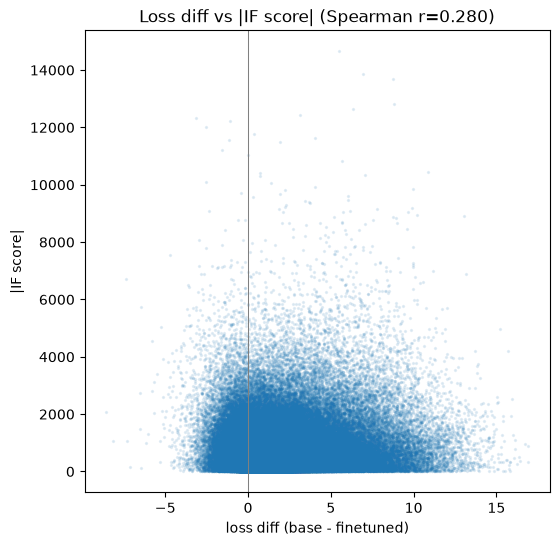

In [24]:
# Isolating the magnitude hypothesis from direction: loss_diff is purely a
# magnitude-side quantity, so correlate it against |score| (magnitude only)
# rather than signed score (magnitude x direction) -- the directional
# component should just be noise relative to loss_diff if the two are
# roughly independent, diluting the signed-score correlation above.
combined["abs_score"] = combined["score"].abs()
corr_abs, pval_abs = spearmanr(combined["loss_diff"], combined["abs_score"])
print(f"Spearman correlation(loss_diff, |score|) = {corr_abs:.4f}  (p={pval_abs:.2e})")

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(combined["loss_diff"], combined["abs_score"], s=2, alpha=0.1, rasterized=True)
ax.axvline(0, color="gray", linewidth=0.75)
ax.set_xlabel("loss diff (base - finetuned)")
ax.set_ylabel("|IF score|")
ax.set_title(f"Loss diff vs |IF score| (Spearman r={corr_abs:.3f})")
fig.savefig(OUTPUT_DIR / f"{output_name}_loss_diff_vs_absscore_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
from scipy.stats import mannwhitneyu


def auroc_extreme_x(df, x_pct, score_col, if_col="score", tail="top"):
    """AUROC for score_col as a predictor of 'is this token in the top/bottom x_pct% by if_col'.
    tail="top": positive class = highest if_col. tail="bottom": positive class = lowest if_col.
    Computed via Mann-Whitney U (AUROC = U / (n_pos * n_neg)) to avoid needing sklearn."""
    if tail == "top":
        threshold = df[if_col].quantile(1 - x_pct / 100)
        is_extreme = (df[if_col] >= threshold).to_numpy()
    else:
        threshold = df[if_col].quantile(x_pct / 100)
        is_extreme = (df[if_col] <= threshold).to_numpy()
    pos = df.loc[is_extreme, score_col].to_numpy()
    neg = df.loc[~is_extreme, score_col].to_numpy()
    U, _ = mannwhitneyu(pos, neg, alternative="two-sided")
    return U / (len(pos) * len(neg))


x_values = [1, 2, 5, 10, 20, 30, 40, 50]
loss_predictors = [("loss_base", "loss_base"), ("loss_finetuned", "loss_finetuned"), ("loss_diff", "loss_diff")]

# Signed IF score, top and bottom tail separately: does loss predict "drives
# the behavior" and "opposes it" symmetrically, or not?
for tail, title in [("top", "top X% most influential tokens (by signed IF score)"),
                     ("bottom", "bottom X% most influential tokens (by signed IF score)")]:
    for score_col, label in loss_predictors:
        aurocs = [auroc_extreme_x(combined, x, score_col=score_col, tail=tail) for x in x_values]
        for x, a in zip(x_values, aurocs):
            print(f"{label:>15}  {tail} {x:>2}% most influential: AUROC = {a:.3f}")
        plt.plot(x_values, aurocs, marker="o", label=label)

    plt.axhline(0.5, color="gray", linestyle="--", label="chance")
    plt.xlabel(title)
    plt.ylabel("AUROC")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"{output_name}_auroc_{tail}.png", dpi=150, bbox_inches="tight")
    plt.show()


In [ ]:
# Magnitude-only framing: predicting the most-influential tokens *regardless
# of direction*, which is the more natural target for a gradient-magnitude-
# driven predictor like loss (loss doesn't carry a sign to match against).
for score_col, label in loss_predictors:
    aurocs = [auroc_extreme_x(combined, x, score_col=score_col, if_col="abs_score", tail="top") for x in x_values]
    for x, a in zip(x_values, aurocs):
        print(f"{label:>15}  top {x:>2}% by |IF score|: AUROC = {a:.3f}")
    plt.plot(x_values, aurocs, marker="o", label=label)

plt.axhline(0.5, color="gray", linestyle="--", label="chance")
plt.xlabel("top X% most influential tokens (by |IF score|)")
plt.ylabel("AUROC")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / f"{output_name}_auroc_magnitude.png", dpi=150, bbox_inches="tight")
plt.show()
